# Matching: estimate an effect when randomisation is impossible

A loyalty programme was offered to customers, but the offer was not
randomised: more engaged customers were more likely to receive it. A naive
comparison therefore mixes the programme effect with pre-existing
differences.

The synthetic data contain a known additive effect of **12**. We will watch
the naive estimate become plausible after matching, inspect balance, and
then vary the distance, bias correction, neighbours and grouping.

**You will use:** `Matching`, Mahalanobis and L2 distances, Abadie–Imbens-
style bias correction, matched indexes and full data, quality tests,
multiple neighbours and `GroupExperiment` via `group_match=True`.

## 1. The problem is confounding, not just unequal sample sizes

For covariates $X$, treatment $D$ and outcome $Y$, our generating process is

$$X ightarrow D,\qquad X ightarrow Y,\qquad D ightarrow Y.$$

Identification relies on **conditional exchangeability**,
$Y(d) \perp D \mid X$, and **overlap**: every treated customer must have a
plausible control counterpart. Matching addresses observed $X$; it cannot
remove confounding from variables we failed to measure.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hypex import Matching
from hypex.dataset import (
    Dataset,
    FeatureRole,
    GroupingRole,
    InfoRole,
    TargetRole,
    TreatmentRole,
)

rng = np.random.default_rng(11)
n_users = 1_200
age = rng.normal(40, 10, n_users)
income = rng.normal(60, 15, n_users)
pre_spend = 20 + 0.5 * age + 0.8 * income + rng.normal(0, 15, n_users)
channel = rng.choice(["app", "web"], n_users)
propensity_logit = (
    -2
    + 0.04 * (age - 40)
    + 0.05 * (income - 60)
    + 0.03 * (pre_spend - 80)
    + 0.4 * (channel == "app")
)
propensity = 1 / (1 + np.exp(-propensity_logit))
treat = rng.binomial(1, propensity)
outcome = (
    10
    + 0.4 * age
    + 0.7 * income
    + 1.1 * pre_spend
    + 12 * treat
    + rng.normal(0, 15, n_users)
)
matching_df = pd.DataFrame(
    {
        "user_id": np.arange(n_users),
        "treat": treat,
        "age": age,
        "income": income,
        "pre_spend": pre_spend,
        "channel": channel,
        "outcome": outcome,
    }
)
matching_df.head()

/Users/danilsamsutdinov/HypEx/.venv/lib/python3.11/site-packages/pyspark/pandas/__init__.py:50: UserWarning: 'PYARROW_IGNORE_TIMEZONE' environment variable was not set. It is required to set this environment variable to '1' in both driver and executor sides if you use pyarrow>=2.0.0. pandas-on-Spark will set it for you but it does not work if there is a Spark context already launched.
  warnings.warn(


,user_id,treat,age,income,pre_spend,channel,outcome
0,0,0,40.341928,44.283612,94.407372,app,181.443741
1,1,0,53.597475,42.664182,85.564922,app,163.225243
2,2,0,52.247211,56.499392,76.866225,web,130.562948
3,3,0,34.896929,43.679513,87.442121,app,150.946801
4,4,1,37.020305,96.829027,113.278793,app,212.567572


In [2]:
naive_effect = (
    matching_df.loc[matching_df.treat == 1, "outcome"].mean()
    - matching_df.loc[matching_df.treat == 0, "outcome"].mean()
)
pd.DataFrame(
    {
        "treatment share": [matching_df.treat.mean()],
        "naive difference": [naive_effect],
        "true additive effect": [12.0],
    }
).round(3)

,treatment share,naive difference,true additive effect
0,0.237,43.657,12.0


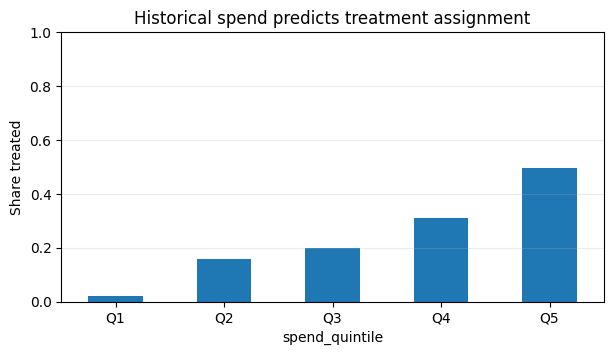

In [3]:
treatment_by_history = (
    matching_df.assign(
        spend_quintile=pd.qcut(
            matching_df.pre_spend, 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
        )
    )
    .groupby("spend_quintile", observed=True)
    .agg(treatment_rate=("treat", "mean"), customers=("treat", "size"))
)
ax = treatment_by_history.treatment_rate.plot(
    kind="bar", figsize=(7, 3.5), ylim=(0, 1), rot=0
)
ax.set_ylabel("Share treated")
ax.set_title("Historical spend predicts treatment assignment")
ax.grid(axis="y", alpha=0.25)
plt.show()

## 2. Declare covariates separately from the outcome

Only pre-treatment variables receive `FeatureRole`. `outcome` remains a
target and is never part of the distance. `channel` is categorical; the
matching pipeline one-hot encodes it into additional fields while retaining
the original column for the chi-square quality check.

In [4]:
roles = {
    "user_id": InfoRole(int),
    "treat": TreatmentRole(int),
    "age": FeatureRole(float),
    "income": FeatureRole(float),
    "pre_spend": FeatureRole(float),
    "channel": FeatureRole(str),
    "outcome": TargetRole(float),
}
matching_data = Dataset(roles=roles, data=matching_df)

### Why Mahalanobis distance?

Euclidean distance treats one unit of every standardised feature alike and
ignores correlation. Mahalanobis distance uses the pooled covariance
matrix $\Sigma$:

$$d_M(x_i,x_j)=\sqrt{(x_i-x_j)^T\Sigma^{-1}(x_i-x_j)}.$$

The whitening step prevents two strongly correlated features from counting
as independent evidence twice. Optional `weights` can then emphasise
substantively important covariates; unspecified features receive weight 1.

In [5]:
mahalanobis_result = Matching(
    distance="mahalanobis",
    weights={"age": 1.0, "income": 1.0, "pre_spend": 2.0},
    bias_estimation=True,
    quality_tests=["t-test", "ks-test", "chi2-test"],
    extract_full_data=True,
    compute_indexes=True,
).execute(matching_data)
mahalanobis_result.summary

,Effect Size,Standard Error,P-value,CI Lower,CI Upper
ATT,11.9276,2.2833,0.0000,7.4524,16.4028
ATC,8.6787,2.9045,0.0028,2.9858,14.3715
ATE,9.4476,2.4653,0.0001,4.6155,14.2796


The shell currently reports all three estimands:

- **ATT**: average effect on treated customers;
- **ATC**: average effect on control customers;
- **ATE**: average effect over both sides.

They need not coincide when effects are heterogeneous. The confidence
intervals account for repeated use of controls as neighbours; repeated
matches must not be treated as independent new observations.

In [6]:
mahalanobis_result.quality_results

,feature,group,TTest pass,TTest p-value,KSTest pass,KSTest p-value,Chi2Test pass,Chi2Test p-value
0,age,0,OK,0.147863,NOT OK,0.002598,NaN,NaN
1,age,1,OK,0.382868,OK,0.759210,NaN,NaN
2,income,0,NOT OK,0.002213,NOT OK,0.000084,NaN,NaN
3,income,1,OK,0.192953,OK,0.309761,NaN,NaN
4,pre_spend,0,NOT OK,0.005015,NOT OK,0.000005,NaN,NaN
5,pre_spend,1,OK,0.323472,OK,0.619195,NaN,NaN
6,channel,0,NaN,NaN,NaN,NaN,OK,0.074383
7,channel,1,NaN,NaN,NaN,NaN,NOT OK,0.000494


Quality tests compare matched pairs on the original covariates. As in A/A,
`OK` means no detected difference. Do not optimise matching until every
p-value exceeds 0.05: p-values depend on sample size and are not balance
metrics. Also inspect standardised mean differences, overlap plots and the
number of unmatched or repeatedly reused observations in a real analysis.

## 3. Separate the design choices

We now compare three estimates: raw L2 matching, Mahalanobis without bias
correction, and the Mahalanobis bias-corrected result above. Bias correction
fits an outcome regression and adjusts for residual covariate imbalance
within matched pairs; it is not a replacement for poor overlap.

In [7]:
l2_result = Matching(
    distance="l2",
    bias_estimation=False,
    quality_tests=["t-test"],
).execute(matching_data)
unadjusted_result = Matching(
    distance="mahalanobis",
    weights={"age": 1.0, "income": 1.0, "pre_spend": 2.0},
    bias_estimation=False,
    quality_tests=["t-test"],
).execute(matching_data)

In [8]:
def get_estimand(output, estimand="ATE"):
    row = output.summary.raw_data.loc[estimand]
    return {
        "effect": row["Effect Size"],
        "CI lower": row["CI Lower"],
        "CI upper": row["CI Upper"],
    }


effect_comparison = pd.DataFrame(
    {
        "naive": {"effect": naive_effect, "CI lower": np.nan, "CI upper": np.nan},
        "L2": get_estimand(l2_result),
        "Mahalanobis": get_estimand(unadjusted_result),
        "Mahalanobis + bias correction": get_estimand(mahalanobis_result),
    }
).T
effect_comparison["CI width"] = (
    effect_comparison["CI upper"] - effect_comparison["CI lower"]
)
effect_comparison.round(3)

,effect,CI lower,CI upper,CI width
naive,43.657,NaN,NaN,NaN
L2,12.030,6.824,17.234,10.410
Mahalanobis,13.562,8.499,18.626,10.127
Mahalanobis + bias correction,9.448,4.616,14.280,9.664


One synthetic run is an illustration, not a benchmark proving that one
distance is universally best. In practice, compare balance and robustness
across defensible specifications rather than selecting the estimate closest
to the answer you want.

## 4. Inspect the actual matched pairs

`compute_indexes=True` enables index extraction, while
`extract_full_data=True` builds the wide original-versus-neighbour table.
The wide table can be expensive, so both are opt-in; in this version the
wide extraction is also needed to materialise `indexes`.

In [9]:
display(mahalanobis_result.indexes.raw_data.head())
pair_columns = [
    "user_id",
    "treat",
    "age",
    "age_matched_0",
    "pre_spend",
    "pre_spend_matched_0",
    "outcome",
    "outcome_matched_0",
]
mahalanobis_result.full_data.raw_data[pair_columns].head()

,indexes_0
0,373
1,256
2,1033
3,650
4,960


,user_id,treat,age,age_matched_0,pre_spend,pre_spend_matched_0,outcome,outcome_matched_0
0,0,0,40.341928,39.863930,94.407372,93.742540,181.443741,198.364699
1,1,0,53.597475,48.036656,85.564922,82.350601,163.225243,170.565164
2,2,0,52.247211,55.331289,76.866225,80.806486,130.562948,187.541081
3,3,0,34.896929,38.857635,87.442121,81.412179,150.946801,142.804863
4,4,1,37.020305,32.573422,113.278793,112.681162,212.567572,223.593330


### More than one neighbour

`n_neighbors=3` averages several counterparts. This can reduce matching
variance but may increase bias if the second and third neighbours are much
farther away. HypEx's quality tests use the first neighbour column; use
additional balance diagnostics when comparing neighbour counts.

In [10]:
three_neighbours = Matching(
    distance="mahalanobis",
    n_neighbors=3,
    quality_tests=[],
).execute(matching_data)
three_neighbours.summary

,Effect Size,Standard Error,P-value,CI Lower,CI Upper
ATT,12.0299,1.6212,0.0,8.8522,15.2075
ATC,10.6299,1.9170,0.0,6.8725,14.3873
ATE,10.9613,1.6931,0.0,7.6427,14.2798


## 5. Exact matching within business segments

Sometimes an app customer should only be matched with an app customer.
Move `channel` to `GroupingRole` and set `group_match=True`: HypEx runs the
whole matching pipeline independently in each group and prefixes the result
columns by segment.

In [11]:
grouped_roles = dict(roles)
grouped_roles["channel"] = GroupingRole(str)
grouped_result = Matching(
    group_match=True,
    distance="mahalanobis",
    quality_tests=["t-test"],
).execute(Dataset(roles=grouped_roles, data=matching_df))
grouped_result.summary

,app Effect Size,app Standard Error,app P-value,app CI Lower,app CI Upper,web Effect Size,web Standard Error,web P-value,web CI Lower,web CI Upper
ATC,11.6089,4.3342,0.0074,3.1139,20.1039,8.8741,3.2193,0.0058,2.5642,15.1840
ATE,12.0963,3.6601,0.0009,4.9226,19.2700,9.1018,2.8642,0.0015,3.4881,14.7156
ATT,13.4838,3.5778,0.0002,6.4713,20.4964,9.9329,2.9978,0.0009,4.0572,15.8085


Segment-specific estimates answer a different question from one pooled ATE.
Check that each segment has enough treated and control observations and
predeclare how they should be combined.

## What matching cannot fix

- **Unobserved confounding.** A great balance table only covers measured X.
- **No overlap.** Do not extrapolate to customers with no credible match.
- **Post-treatment covariates.** Matching on them can block or create causal
  paths.
- **Too many noisy features.** Distances become less informative in high
  dimensions; prioritise prognostic pre-treatment covariates.

**Next:** [Compose custom pipelines](04_Custom_Pipelines.ipynb).